# Grupo 11 — E3: ViT-B/16, compresión y robustez (notebook final)
**Estado: protocolo listo para ejecutar; resultados finales pendientes.** No interpretar salidas anteriores de E2 como evidencia E3.

**Fase A:** baseline y teardown. **Fase B:** FP16 real y sensibilidad fake-PTQ INT8/INT4 (MHSA/MLP). **Fase C:** CIFAR-10-C con corrupciones/severidades predefinidas y comparación controlada.

**H1 (pre-registrada en E2):** cuantizar MHSA produce más pérdida de accuracy que cuantizar MLP a igualdad de bits. **H2 (E3, antes de ejecutar):** las versiones cuantizadas tendrán una mayor pérdida de precisión relativa al clean que FP32 bajo corrupciones.

**Honestidad:** fake-PTQ restaura pesos FP32 y NO acelera inferencia ni reduce checkpoint; INT4 es únicamente simulado. FP16 sí reduce tamaño. La cuantización real INT8 empaquetada y sus aceleraciones no se implementan en este cuaderno y deben declararse limitaciones. El fine-tuning de CIFAR-10 es adaptación por transferencia, no reproducción exacta de un paper.


In [1]:
# 1. Entorno y almacenamiento persistente por integrante
import sys, subprocess, os, json, time, random, copy, math, pathlib, io, platform, hashlib, tarfile
subprocess.check_call([sys.executable,'-m','pip','-q','install','pandas','matplotlib','tqdm'])
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torchvision
from torch import nn
from torchvision.models import vit_b_16, ViT_B_16_Weights
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset, Dataset
from tqdm.auto import tqdm
from PIL import Image
from google.colab import drive
drive.mount('/content/drive')
HOME=pathlib.Path('/content/drive/MyDrive')
HUB_CACHE=HOME/'Grupo11_ViT_cache'/'hub'
HUB_CACHE.mkdir(parents=True,exist_ok=True)
torch.hub.set_dir(str(HUB_CACHE))  # reutiliza el archivo vit_b_16-c867db91.pth ya guardado
DATA_ROOT=HOME/'Grupo11_ViT_datasets'
DATA_ROOT.mkdir(parents=True,exist_ok=True)
CKPT_DIR=HOME/'Grupo11_ViT_checkpoints'
CKPT_DIR.mkdir(parents=True,exist_ok=True)
ROOT=pathlib.Path('/content/grupo11_e3_outputs')
ROOT.mkdir(parents=True,exist_ok=True)
SEED=42
random.seed(SEED);np.random.seed(SEED);torch.manual_seed(SEED)
if torch.cuda.is_available():torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark=False
assert torch.cuda.is_available(),'Usar GPU T4 o superior en Google Colab para E3.'
DEVICE=torch.device('cuda')
print('Dispositivo:',torch.cuda.get_device_name(0),'| PyTorch:',torch.__version__,'| torchvision:',torchvision.__version__)
print('Pesos:',HUB_CACHE,'| Datos:',DATA_ROOT,'| Checkpoints:',CKPT_DIR)


Mounted at /content/drive
Dispositivo: Tesla T4 | PyTorch: 2.11.0+cu130 | torchvision: 0.26.0+cu130
Pesos: /content/drive/MyDrive/Grupo11_ViT_cache/hub | Datos: /content/drive/MyDrive/Grupo11_ViT_datasets | Checkpoints: /content/drive/MyDrive/Grupo11_ViT_checkpoints


## 2. Baseline: entrenamiento y evaluación CIFAR-10

El split de 50 000 ejemplos se divide en 5 000 validación y 45 000 entrenamiento mediante semilla 42. Por defecto se entrena con **15 000** ejemplos y 3 épocas (corrida E3 de alcance intermedio); para protocolo ampliado cambiar `N_TRAIN=45000` y entrenar de nuevo. El test oficial de **10 000** ejemplos no se usa para seleccionar modelos.

**Caché:** CIFAR-10 y los pesos originales quedan en Drive. El checkpoint E3 tiene nombre único para no confundirlo con el exploratorio E2. Si cambias hiperparámetros se crea un checkpoint diferente.


In [2]:
WEIGHTS=ViT_B_16_Weights.IMAGENET1K_V1
norm=transforms.Normalize(mean=[.485,.456,.406],std=[.229,.224,.225])
train_tf=transforms.Compose([transforms.Resize((224,224)),transforms.RandomHorizontalFlip(),transforms.ToTensor(),norm])
eval_tf=transforms.Compose([transforms.Resize((224,224)),transforms.ToTensor(),norm])
raw_train=datasets.CIFAR10(root=str(DATA_ROOT/'cifar10'),train=True,download=True,transform=train_tf)
raw_val=datasets.CIFAR10(root=str(DATA_ROOT/'cifar10'),train=True,download=False,transform=eval_tf)
raw_test=datasets.CIFAR10(root=str(DATA_ROOT/'cifar10'),train=False,download=True,transform=eval_tf)
perm=np.random.default_rng(SEED).permutation(len(raw_train))
val_ids=perm[:5000]
all_train_ids=perm[5000:]
N_TRAIN=15000  # cambiar a 45000 para protocolo ampliado, genera otro checkpoint
N_VAL_EVAL=5000
N_TEST_EVAL=10000
BATCH=16  # conservador para Tesla T4
WORKERS=2
EPOCHS=3
LR=3e-5
train_ids=all_train_ids[:N_TRAIN]
train_loader=DataLoader(Subset(raw_train,train_ids.tolist()),batch_size=BATCH,shuffle=True,num_workers=WORKERS,pin_memory=True)
val_loader=DataLoader(Subset(raw_val,val_ids[:N_VAL_EVAL].tolist()),batch_size=BATCH,shuffle=False,num_workers=WORKERS,pin_memory=True)
test_loader=DataLoader(Subset(raw_test,list(range(N_TEST_EVAL))),batch_size=BATCH,shuffle=False,num_workers=WORKERS,pin_memory=True)
model=vit_b_16(weights=WEIGHTS)
model.heads.head=nn.Linear(model.heads.head.in_features,10)
model.to(DEVICE)
print('Train/val/test:',len(train_ids),N_VAL_EVAL,N_TEST_EVAL)


100%|██████████| 170M/170M [40:49<00:00, 69.6kB/s]


Train/val/test: 15000 5000 10000


In [3]:
# Fine-tuning últimos 2 encoder blocks + cabeza.
# Nunca cargar el checkpoint E2 en E3 sin documentar el cambio de protocolo.
FORCE_RETRAIN=False
for p in model.parameters():p.requires_grad=False
for block in list(model.encoder.layers.children())[-2:]:
    for p in block.parameters():p.requires_grad=True
for p in model.heads.parameters():p.requires_grad=True

@torch.inference_mode()
def accuracy(net,loader,device=DEVICE):
    net.eval();good=total=0
    for x,y in loader:
        pred=net(x.to(device)).argmax(1).cpu()
        good+=(pred==y).sum().item();total+=len(y)
    return 100*good/total

ckpt=CKPT_DIR/f'vit_cifar10_E3_n{N_TRAIN}_ep{EPOCHS}_seed{SEED}_last2_b{BATCH}.pt'
hist_file=CKPT_DIR/f'{ckpt.stem}_history.csv'
TRAIN=FORCE_RETRAIN or not ckpt.exists()
print('Checkpoint:',ckpt,'| Entrenar:',TRAIN)
if TRAIN:
    opt=torch.optim.AdamW((p for p in model.parameters() if p.requires_grad),lr=LR,weight_decay=.01)
    best=-1;history=[]
    for epoch in range(EPOCHS):
        model.train();loss_sum=0
        for x,y in tqdm(train_loader,desc=f'E3 epoch {epoch+1}/{EPOCHS}'):
            x,y=x.to(DEVICE),y.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            logits=model(x)
            loss=nn.functional.cross_entropy(logits,y)
            loss.backward();opt.step();loss_sum+=loss.item()
        va=accuracy(model,val_loader)
        history.append({'epoch':epoch+1,'sum_train_batch_losses':loss_sum,'val_accuracy_top1_pct':va})
        print('Epoch:',epoch+1,'val:',round(va,3))
        if va>best:
            best=va
            torch.save({'model':model.state_dict(),'val_best':best,'seed':SEED,'n_train':N_TRAIN,'epochs_config':EPOCHS,'batch':BATCH,'lr':LR,'train_last_blocks':2},ckpt)
    pd.DataFrame(history).to_csv(hist_file,index=False)
else:
    print('Se reutiliza checkpoint E3 y no se reentrena.')
payload=torch.load(ckpt,map_location='cpu',weights_only=True)
assert payload['n_train']==N_TRAIN and payload['seed']==SEED and payload['epochs_config']==EPOCHS
model.load_state_dict(payload['model'])
model.to(DEVICE).eval()
print('Mejor val:',payload['val_best'],'| Test clean:',accuracy(model,test_loader))


Checkpoint: /content/drive/MyDrive/Grupo11_ViT_checkpoints/vit_cifar10_E3_n15000_ep3_seed42_last2_b16.pt | Entrenar: True


E3 epoch 1/3:   0%|          | 0/938 [00:00<?, ?it/s]

Epoch: 1 val: 95.0


E3 epoch 2/3:   0%|          | 0/938 [00:00<?, ?it/s]

Epoch: 2 val: 95.64


E3 epoch 3/3:   0%|          | 0/938 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x787c989c77e0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'Exception ignored in: 
<function _MultiProcessingDataLoaderIter.__del__ at 0x787c989c77e0>
AssertionError: Traceback (most recent call last):
can only test a child process  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__

    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch: 3 val: 95.26
Mejor val: 95.64 | Test clean: 95.6


## 3. Fase A: teardown instrumentado
Los FLOPs son **estimaciones analíticas** por bloque; las visualizaciones de CLS son similitudes, no mapas de atención causal. El gradiente espacial es un proxy de influencia efectiva, no receptivo teórico.


In [4]:
# Parámetros por bloque / módulo
rows=[]
for i,block in enumerate(model.encoder.layers):
    mha=block.self_attention
    rows.append({'bloque':i+1,'params_totales':sum(p.numel() for p in block.parameters()),
                 'params_MHSA':sum(p.numel() for p in mha.parameters()),
                 'params_MLP':sum(p.numel() for p in block.mlp.parameters())})
params=pd.DataFrame(rows)
# Conteo aproximado de MACs y FLOPs por bloque con B=1, tokens=197, D=768, MLP=3072
N=197;D=768;H=3072
macs_qkv=3*N*D*D
macs_out=N*D*D
macs_attention=2*N*N*D
macs_mlp=2*N*D*H
block_flops=2*(macs_qkv+macs_out+macs_attention+macs_mlp)
params['FLOPs_aprox']=block_flops
params.to_csv(ROOT/'teardown_por_bloque.csv',index=False)
display(params)
print('Parámetros modelo:',sum(p.numel() for p in model.parameters()))
print('FLOPs aproximados de 12 encoder blocks:',12*block_flops/1e9,'GFLOPs (sin patch embedding/head)')


,bloque,params_totales,params_MHSA,params_MLP,FLOPs_aprox
0,1,7087872,2362368,4722432,2907909120
1,2,7087872,2362368,4722432,2907909120
2,3,7087872,2362368,4722432,2907909120
3,4,7087872,2362368,4722432,2907909120
4,5,7087872,2362368,4722432,2907909120
5,6,7087872,2362368,4722432,2907909120
6,7,7087872,2362368,4722432,2907909120
7,8,7087872,2362368,4722432,2907909120
8,9,7087872,2362368,4722432,2907909120
9,10,7087872,2362368,4722432,2907909120


Parámetros modelo: 85806346
FLOPs aproximados de 12 encoder blocks: 34.89490944 GFLOPs (sin patch embedding/head)


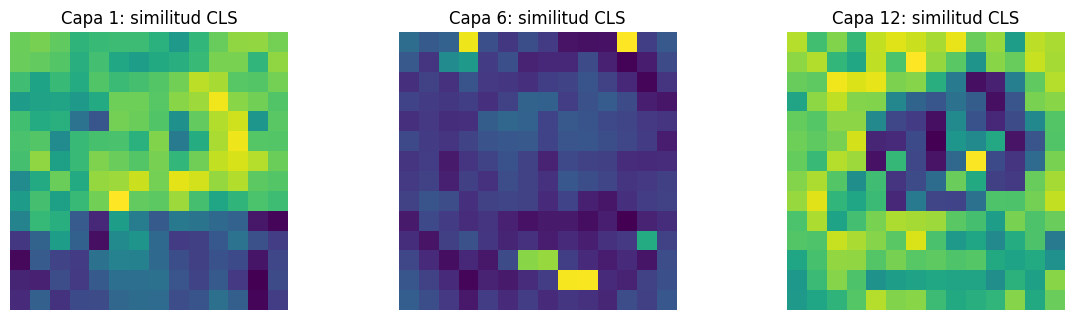

Estos mapas NO sustituyen una medición de campo receptivo efectivo.


In [5]:
# Activaciones intermedias a través de hooks y mapas aproximados de similitud CLS-patches
acts={}; handles=[]
for ix in [0,5,11]:
    block=list(model.encoder.layers)[ix]
    def mk(k):
        def cb(module, inputs, output): acts[k]=output.detach().cpu()
        return cb
    handles.append(block.register_forward_hook(mk(ix+1)))
xb,yb=next(iter(test_loader))
with torch.inference_mode(): _=model(xb[:1].to(DEVICE))
for h in handles: h.remove()
fig,axs=plt.subplots(1,3,figsize=(12,3.3))
for ax,(layer,activation) in zip(axs,acts.items()):
    # Similitud coseno de representación CLS frente a patches (no es mapa de atención exacto ni campo receptivo causal)
    t=activation[0]; scores=nn.functional.cosine_similarity(t[0:1],t[1:],dim=-1).reshape(14,14)
    ax.imshow(scores,interpolation='nearest');ax.set_title(f'Capa {layer}: similitud CLS');ax.axis('off')
plt.tight_layout();plt.savefig(ROOT/'features_intermedias.png',dpi=150);plt.show()
print('Estos mapas NO sustituyen una medición de campo receptivo efectivo.')


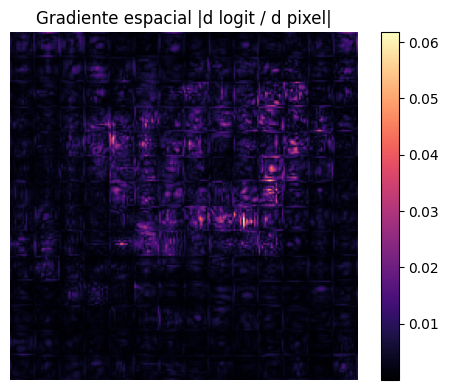

Mapa de sensibilidad local al input, no campo receptivo teórico.


In [6]:
# Campo de influencia efectivo: gradiente de logit de clase predicha sobre la imagen (proxy local)
model.eval()
x=xb[:1].to(DEVICE).clone().detach().requires_grad_(True)
with torch.enable_grad():
    out=model(x);target=out[0,out.argmax(1).item()]; grad=torch.autograd.grad(target,x)[0]
saliency=grad.abs().amax(dim=1)[0].detach().cpu()
plt.figure(figsize=(5,4));plt.imshow(saliency,cmap='magma');plt.title('Gradiente espacial |d logit / d pixel|');plt.colorbar();plt.axis('off')
plt.tight_layout();plt.savefig(ROOT/'campo_influencia_gradiente.png',dpi=150);plt.show()
print('Mapa de sensibilidad local al input, no campo receptivo teórico.')


In [7]:
# Medición rigurosa de latencia: sincronizar CUDA y excluir warmup; mismo batch para todas las variantes
import statistics
@torch.inference_mode()
def profile(model, loader, device, batches=30, warmup=8):
    model.eval(); x=next(iter(loader))[0].to(device)
    for _ in range(warmup): _=model(x)
    if device.type=='cuda': torch.cuda.synchronize();torch.cuda.reset_peak_memory_stats(device)
    times=[]
    for _ in range(batches):
        if device.type=='cuda':torch.cuda.synchronize()
        start=time.perf_counter();_=model(x)
        if device.type=='cuda':torch.cuda.synchronize()
        times.append((time.perf_counter()-start)*1000/x.shape[0])
    mem=torch.cuda.max_memory_allocated(device)/2**20 if device.type=='cuda' else None
    return {'latencia_ms_img_mediana':statistics.median(times),'latencia_ms_img_p90':float(np.percentile(times,90)),
            'VRAM_pico_MiB':mem,'batch':len(x),'device':str(device)}
def size_mb(model):
    b=io.BytesIO();torch.save(model.state_dict(),b);return len(b.getvalue())/1e6
baseline={'experimento':'FP32_baseline','tipo':'FP32 real','accuracy_top1_pct':accuracy(model,test_loader),
          'tamano_checkpoint_MB':size_mb(model),**profile(model,test_loader,DEVICE)}
print(baseline)


{'experimento': 'FP32_baseline', 'tipo': 'FP32 real', 'accuracy_top1_pct': 95.6, 'tamano_checkpoint_MB': 343.285519, 'latencia_ms_img_mediana': 15.07419962499057, 'latencia_ms_img_p90': 15.13720869375561, 'VRAM_pico_MiB': 639.71630859375, 'batch': 16, 'device': 'cuda'}


## 4. Fase B: intervenciones y ablaciones
**H1 fijada antes de los resultados:** la alteración numérica de MHSA causa mayor pérdida de precisión que la de MLP a igual nivel de cuantización. Comparaciones: FP32, fake-INT8 MHSA/MLP, fake-INT4 MHSA/MLP, FP16 real. **Fake-INT8/INT4 no es cuantización INT8/INT4 empaquetada:** el almacenamiento permanece FP32. No informar mejora de tamaño ni velocidad como beneficio de fake-quant.


In [8]:
# PTQ simulado selectivo para MHSA o MLP: cuantiza y restaura pesos, no cambia arquitectura
@torch.no_grad()
def fake_quantize_tensor_(param, bits=8):
    max_abs=param.data.abs().max()
    if max_abs == 0: return
    qmax=(2**(bits-1))-1
    scale=max_abs/qmax
    quant=torch.clamp(torch.round(param.data/scale),-qmax,qmax)
    param.data.copy_(quant*scale)

def simulated_quant_model(base, target='mhsa', bits=8):
    clone=copy.deepcopy(base).to('cpu')
    for layer in clone.encoder.layers:
        module=layer.self_attention if target=='mhsa' else layer.mlp if target=='mlp' else None
        if module is None: raise ValueError(target)
        for name,p in module.named_parameters():
            if p.ndim>=2: fake_quantize_tensor_(p,bits)
    return clone.to(DEVICE).eval()

results=[baseline]
# Misma semilla, mismo test, mismo tamaño de batch y hardware
for bits,target in [(8,'mhsa'),(8,'mlp'),(4,'mhsa'),(4,'mlp')]:
    variant=simulated_quant_model(model,target=target,bits=bits)
    row={'experimento':f'FakeINT{bits}_{target.upper()}',
         'tipo':f'simulación PTQ {bits} bits sobre pesos; almacenamiento FP32',
         'accuracy_top1_pct':accuracy(variant,test_loader),
         'tamano_checkpoint_MB':size_mb(variant),**profile(variant,test_loader,DEVICE)}
    results.append(row);print(row)
    del variant
    if DEVICE.type=='cuda':torch.cuda.empty_cache()
df=pd.DataFrame(results)
df['caida_pp_vs_FP32']=baseline['accuracy_top1_pct']-df['accuracy_top1_pct']
df.to_csv(ROOT/'resultados_e2.csv',index=False)
display(df)


{'experimento': 'FakeINT8_MHSA', 'tipo': 'simulación PTQ 8 bits sobre pesos; almacenamiento FP32', 'accuracy_top1_pct': 95.58, 'tamano_checkpoint_MB': 343.285519, 'latencia_ms_img_mediana': 15.073925062495164, 'latencia_ms_img_p90': 15.16631059998872, 'VRAM_pico_MiB': 969.6357421875, 'batch': 16, 'device': 'cuda'}
{'experimento': 'FakeINT8_MLP', 'tipo': 'simulación PTQ 8 bits sobre pesos; almacenamiento FP32', 'accuracy_top1_pct': 95.56, 'tamano_checkpoint_MB': 343.285519, 'latencia_ms_img_mediana': 15.07620365623552, 'latencia_ms_img_p90': 15.140607050000199, 'VRAM_pico_MiB': 969.6357421875, 'batch': 16, 'device': 'cuda'}
{'experimento': 'FakeINT4_MHSA', 'tipo': 'simulación PTQ 4 bits sobre pesos; almacenamiento FP32', 'accuracy_top1_pct': 91.25, 'tamano_checkpoint_MB': 343.285519, 'latencia_ms_img_mediana': 15.100672968742401, 'latencia_ms_img_p90': 15.150369643720296, 'VRAM_pico_MiB': 969.6357421875, 'batch': 16, 'device': 'cuda'}
{'experimento': 'FakeINT4_MLP', 'tipo': 'simulación 

,experimento,tipo,accuracy_top1_pct,tamano_checkpoint_MB,latencia_ms_img_mediana,latencia_ms_img_p90,VRAM_pico_MiB,batch,device,caida_pp_vs_FP32
0,FP32_baseline,FP32 real,95.60,343.285519,15.074200,15.137209,639.716309,16,cuda,0.00
1,FakeINT8_MHSA,simulación PTQ 8 bits sobre pesos; almacenamie...,95.58,343.285519,15.073925,15.166311,969.635742,16,cuda,0.02
2,FakeINT8_MLP,simulación PTQ 8 bits sobre pesos; almacenamie...,95.56,343.285519,15.076204,15.140607,969.635742,16,cuda,0.04
3,FakeINT4_MHSA,simulación PTQ 4 bits sobre pesos; almacenamie...,91.25,343.285519,15.100673,15.150370,969.635742,16,cuda,4.35
4,FakeINT4_MLP,simulación PTQ 4 bits sobre pesos; almacenamie...,12.32,343.285519,14.485239,14.730277,969.635742,16,cuda,83.28


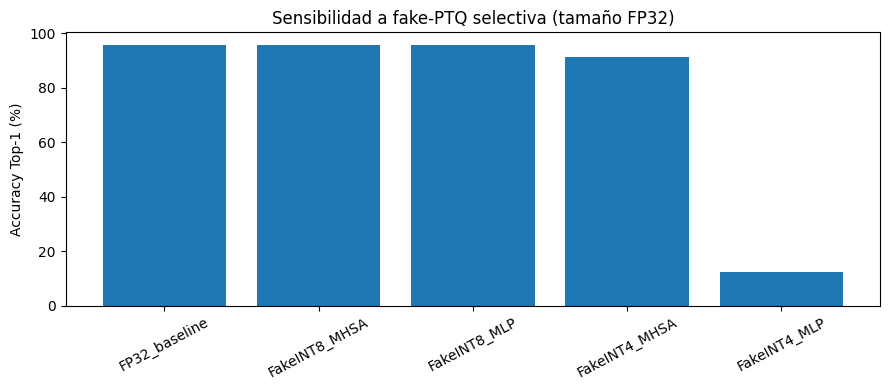

FakeINT8, MHSA - MLP (pp): 0.02
FakeINT4, MHSA - MLP (pp): 78.93


In [9]:
# Resultados de sensibilidad numérica; no son ratios de compresión reales
fig,ax=plt.subplots(figsize=(9,4))
ax.bar(df.experimento,df.accuracy_top1_pct)
ax.set_ylabel('Accuracy Top-1 (%)')
ax.set_title('Sensibilidad a fake-PTQ selectiva (tamaño FP32)')
ax.tick_params(axis='x',rotation=28)
plt.tight_layout();plt.savefig(ROOT/'ablacion_accuracy.png',dpi=160);plt.show()
for bits in (8,4):
    a=df.loc[df.experimento==f'FakeINT{bits}_MHSA','accuracy_top1_pct'].iloc[0]
    b=df.loc[df.experimento==f'FakeINT{bits}_MLP','accuracy_top1_pct'].iloc[0]
    print(f'FakeINT{bits}, MHSA - MLP (pp):',round(a-b,4))


## 4. FP16 real (GPU) y tamaño
Si existe CUDA se convierte a `half()` y se evalúa con entradas half; comparar con FP32 bajo la misma GPU. En CPU se omite explícitamente. Esto **sí** cambia precisión y almacenamiento, pero una mejora de latencia no está garantizada.

In [10]:
if DEVICE.type=='cuda':
    half_model=copy.deepcopy(model).half().eval()
    @torch.inference_mode()
    def acc_half(m,loader):
        good=total=0
        for xx,yy in loader:
            preds=m(xx.to(DEVICE).half()).argmax(1).cpu()
            good+=(preds==yy).sum().item();total+=len(yy)
        return 100*good/total
    # wrapper ejecuta las mismas entradas en FP16
    class HalfInput(nn.Module):
        def __init__(self,net):super().__init__();self.net=net
        def forward(self,x):return self.net(x.half())
    half_wrapper=HalfInput(half_model).to(DEVICE).eval()
    f16={'experimento':'FP16_real','tipo':'pesos y activaciones FP16',
         'accuracy_top1_pct':acc_half(half_model,test_loader),'tamano_checkpoint_MB':size_mb(half_model),
         **profile(half_wrapper,test_loader,DEVICE)}
    print(f16)
    df=pd.concat([df,pd.DataFrame([f16])],ignore_index=True)
    df.to_csv(ROOT/'resultados_e2.csv',index=False)
    del half_wrapper,half_model
    torch.cuda.empty_cache()
    model.to(DEVICE).eval()  # recuperar FP32 para la Fase C
else:
    print('No hay GPU; no se ejecuta el experimento FP16 real.')


{'experimento': 'FP16_real', 'tipo': 'pesos y activaciones FP16', 'accuracy_top1_pct': 95.61, 'tamano_checkpoint_MB': 171.672847, 'latencia_ms_img_mediana': 2.985050843733461, 'latencia_ms_img_p90': 3.0518882125477376, 'VRAM_pico_MiB': 759.44970703125, 'batch': 16, 'device': 'cuda'}


## 6. Fase C — shift de dominio con CIFAR-10-C

Fuente oficial: Hendrycks y Dietterich, *Benchmarking Neural Network Robustness to Common Corruptions and Perturbations* (ICLR 2019), Zenodo DOI 10.5281/zenodo.2535967. El archivo original pesa ~2.9 GB, por lo que **NO se versiona en GitHub**; se guarda una vez en Drive de cada integrante. Se verificará MD5 `56bf5dcef84df0e2308c6dcbcbbd8499`.

En el protocolo predeterminado se usan tres corrupciones (`gaussian_noise`, `defocus_blur`, `fog`), tres severidades (1,3,5) y 2 000 ejemplos por condición; se reporta exactamente ese alcance. Para evaluación más extensa, poner `N_CORRUPT=10000` y seleccionar más corrupciones. La primera ejecución requiere espacio suficiente en Drive y descarga considerable. Mismas imágenes, preprocesamiento y batch para todas las variantes.


In [11]:
# Descarga persistente oficial con reanudación de wget -c e integridad MD5
CIFAR_C_URL='https://zenodo.org/records/2535967/files/CIFAR-10-C.tar?download=1'
CIFAR_C_MD5='56bf5dcef84df0e2308c6dcbcbbd8499'
CIFAR_C_ROOT=DATA_ROOT/'CIFAR-10-C'
CIFAR_C_ROOT.mkdir(parents=True,exist_ok=True)
ARCHIVE=DATA_ROOT/'CIFAR-10-C.tar'
CORRUPTIONS=['gaussian_noise','defocus_blur','fog']
SEVERITIES=[1,3,5]
N_CORRUPT=2000  # 10000 para todas las imágenes por severidad
assert 1<=N_CORRUPT<=10000
def file_md5(path):
    h=hashlib.md5()
    with open(path,'rb') as f:
        for part in iter(lambda:f.read(8*1024*1024),b''):h.update(part)
    return h.hexdigest()

selected=[c+'.npy' for c in CORRUPTIONS]+['labels.npy']
if not all((CIFAR_C_ROOT/s).exists() for s in selected):
    if not ARCHIVE.exists() or file_md5(ARCHIVE)!=CIFAR_C_MD5:
        print('Descargando CIFAR-10-C en Drive; requiere ~2.9 GB...')
        subprocess.check_call(['wget','-c','--tries=8','--timeout=60','-O',str(ARCHIVE),CIFAR_C_URL])
    assert file_md5(ARCHIVE)==CIFAR_C_MD5,'El archivo CIFAR-10-C.tar está incompleto o corrupto.'
    with tarfile.open(ARCHIVE,'r') as tf:
        members={}
        for m in tf.getmembers():
            if m.isfile() and pathlib.PurePosixPath(m.name).name in selected:
                members[pathlib.PurePosixPath(m.name).name]=m
        assert set(members)==set(selected),f'Faltan archivos: {set(selected)-set(members)}'
        for name,m in members.items():
            path=CIFAR_C_ROOT/name
            if not path.exists():
                with tf.extractfile(m) as src,open(path,'wb') as out:
                    import shutil
                    shutil.copyfileobj(src,out)
    print('Extraídas solo las corrupciones escogidas.')
print('Datos CIFAR-10-C:',CIFAR_C_ROOT)


Descargando CIFAR-10-C en Drive; requiere ~2.9 GB...
Extraídas solo las corrupciones escogidas.
Datos CIFAR-10-C: /content/drive/MyDrive/Grupo11_ViT_datasets/CIFAR-10-C


In [12]:
# Dataset de severidad controlada: 10k ejemplos por bloque de severidad
class CIFAR10Corruption(Dataset):
    def __init__(self,root,corruption,severity,limit,transform):
        assert severity in range(1,6)
        self.array=np.load(root/f'{corruption}.npy',mmap_mode='r')
        self.labels=np.load(root/'labels.npy',mmap_mode='r')
        self.start=(severity-1)*10000;self.limit=limit;self.transform=transform
        assert self.array.shape[0]==50000 and len(self.labels)>=10000
    def __len__(self):return self.limit
    def __getitem__(self,index):
        k=self.start+index
        # labels.npy oficial contiene 10000 labels o 50000 repetidas
        y=int(self.labels[index if len(self.labels)==10000 else k])
        return self.transform(Image.fromarray(np.array(self.array[k]))),y

def make_c_loader(corruption,severity):
    ds=CIFAR10Corruption(CIFAR_C_ROOT,corruption,severity,N_CORRUPT,eval_tf)
    return DataLoader(ds,batch_size=BATCH,shuffle=False,num_workers=WORKERS,pin_memory=True)
# Corroborar alineación de etiquetas del test: CIFAR-10-C comparte orden del test oficial
assert np.array_equal(np.array(raw_test.targets[:N_CORRUPT]),np.load(CIFAR_C_ROOT/'labels.npy')[:N_CORRUPT])
print('Etiquetas CIFAR-10-C alineadas con test CIFAR-10.')


Etiquetas CIFAR-10-C alineadas con test CIFAR-10.


In [13]:
# Evaluar las mismas condiciones en FP32, FP16 y fakeINT8 (y opcional INT4)
# Cambiar INCLUDE_INT4_C=True para repetir Fase C también en fakeINT4.
INCLUDE_INT4_C=False
c_variants=['FP32_baseline','FP16_real','FakeINT8_MHSA','FakeINT8_MLP']
if INCLUDE_INT4_C:c_variants+=['FakeINT4_MHSA','FakeINT4_MLP']
c_rows=[]
for variant_name in c_variants:
    print('Robustez:',variant_name)
    if variant_name=='FP32_baseline':
        v=model.to(DEVICE).eval()
    elif variant_name=='FP16_real':
        v=copy.deepcopy(model).to('cpu').half().to(DEVICE).eval()
    else:
        b=int(variant_name.split('_')[0].replace('FakeINT',''))
        target=variant_name.split('_')[1].lower()
        v=simulated_quant_model(model,target=target,bits=b)
    for corruption in CORRUPTIONS:
        for sev in SEVERITIES:
            loader=make_c_loader(corruption,sev)
            if variant_name=='FP16_real':
                @torch.inference_mode()
                def eval_half():
                    good=total=0
                    for x,y in loader:
                        p=v(x.to(DEVICE).half()).argmax(1).cpu()
                        good+=(p==y).sum().item();total+=len(y)
                    return 100*good/total
                acc=eval_half()
            else:acc=accuracy(v,loader)
            c_rows.append({'experimento':variant_name,'corrupcion':corruption,'severidad':sev,'n_imagenes':N_CORRUPT,'accuracy_top1_pct':acc})
            print(corruption,sev,round(acc,3))
    if variant_name!='FP32_baseline':
        del v
        torch.cuda.empty_cache()
    else:
        del v
model.to(DEVICE).eval()
df_c=pd.DataFrame(c_rows)
df_c.to_csv(ROOT/'resultados_cifar10c.csv',index=False)
display(df_c)


Robustez: FP32_baseline
gaussian_noise 1 88.65
gaussian_noise 3 69.35
gaussian_noise 5 57.05
defocus_blur 1 95.15
defocus_blur 3 91.35
defocus_blur 5 79.75
fog 1 95.75
fog 3 91.5
fog 5 65.25
Robustez: FP16_real
gaussian_noise 1 88.7
gaussian_noise 3 69.35
gaussian_noise 5 57.05
defocus_blur 1 95.15
defocus_blur 3 91.35
defocus_blur 5 79.75
fog 1 95.7
fog 3 91.5
fog 5 65.25
Robustez: FakeINT8_MHSA
gaussian_noise 1 88.55
gaussian_noise 3 69.25
gaussian_noise 5 57.15
defocus_blur 1 95.1
defocus_blur 3 91.35
defocus_blur 5 79.75
fog 1 95.65
fog 3 91.65
fog 5 65.3
Robustez: FakeINT8_MLP
gaussian_noise 1 88.75
gaussian_noise 3 69.8
gaussian_noise 5 57.5
defocus_blur 1 95.2
defocus_blur 3 91.25
defocus_blur 5 79.35
fog 1 95.6
fog 3 91.35
fog 5 65.7


,experimento,corrupcion,severidad,n_imagenes,accuracy_top1_pct
0,FP32_baseline,gaussian_noise,1,2000,88.65
1,FP32_baseline,gaussian_noise,3,2000,69.35
2,FP32_baseline,gaussian_noise,5,2000,57.05
3,FP32_baseline,defocus_blur,1,2000,95.15
4,FP32_baseline,defocus_blur,3,2000,91.35
5,FP32_baseline,defocus_blur,5,2000,79.75
6,FP32_baseline,fog,1,2000,95.75
7,FP32_baseline,fog,3,2000,91.50
8,FP32_baseline,fog,5,2000,65.25
9,FP16_real,gaussian_noise,1,2000,88.70


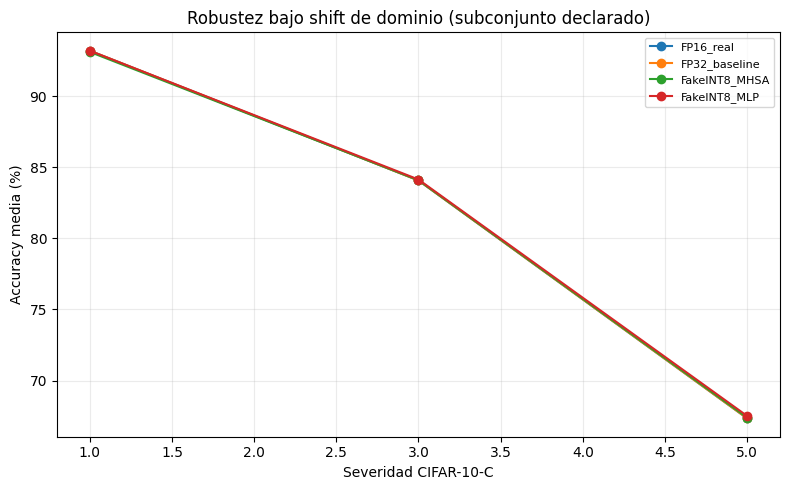

,experimento,severidad,accuracy_media_pct,caida_media_pp
0,FP16_real,1,93.183333,2.426667
1,FP16_real,3,84.066667,11.543333
2,FP16_real,5,67.350000,28.260000
3,FP32_baseline,1,93.183333,2.416667
4,FP32_baseline,3,84.066667,11.533333
5,FP32_baseline,5,67.350000,28.250000
6,FakeINT8_MHSA,1,93.100000,2.480000
7,FakeINT8_MHSA,3,84.083333,11.496667
8,FakeINT8_MHSA,5,67.400000,28.180000
9,FakeINT8_MLP,1,93.183333,2.376667


In [14]:
# Gráficos, caída clean→corrupto y agregados por severidad
clean_acc={row['experimento']:float(row['accuracy_top1_pct']) for _,row in df.iterrows()}
df_c['clean_accuracy_pct']=df_c['experimento'].map(clean_acc)
df_c['caida_pp_clean_c']=df_c['clean_accuracy_pct']-df_c['accuracy_top1_pct']
df_c.to_csv(ROOT/'resultados_cifar10c.csv',index=False)
summ=df_c.groupby(['experimento','severidad'],as_index=False).agg(
    accuracy_media_pct=('accuracy_top1_pct','mean'),
    caida_media_pp=('caida_pp_clean_c','mean'))
summ.to_csv(ROOT/'resumen_robustez.csv',index=False)
fig,ax=plt.subplots(figsize=(8,5))
for name,g in summ.groupby('experimento'):
    ax.plot(g.severidad,g.accuracy_media_pct,marker='o',label=name)
ax.set_xlabel('Severidad CIFAR-10-C')
ax.set_ylabel('Accuracy media (%)')
ax.set_title('Robustez bajo shift de dominio (subconjunto declarado)')
ax.legend(fontsize=8);ax.grid(alpha=.25)
plt.tight_layout();plt.savefig(ROOT/'robustez_severidad.png',dpi=180);plt.show()
display(summ)


## 7. Resultados y trazabilidad
Las cifras se producen **solo cuando el notebook es ejecutado**; el GitHub incluye el protocolo, no resultados inventados. Los archivos de salida se generan en `/content/grupo11_e3_outputs` y el ZIP en `/content/grupo11_e3_resultados.zip`. Subir CSV/PNG de la corrida ejecutada a `results/e3/` y documentar GPU, particiones, límites y hallazgos en `DESIGN_LOG.md`.


In [15]:
# Manifiesto reproducible del experimento y ZIP (sin pesos grandes ni datasets)
config={'seed':SEED,'pytorch':torch.__version__,'torchvision':torchvision.__version__,
        'hardware':torch.cuda.get_device_name(0),'device':str(DEVICE),
        'weights':'ViT_B_16_Weights.IMAGENET1K_V1','input_shape':[3,224,224],
        'normalization':'ImageNet mean/std','N_TRAIN':N_TRAIN,'VAL':N_VAL_EVAL,'TEST':N_TEST_EVAL,
        'batch':BATCH,'epochs':EPOCHS,'lr':LR,'train_last_blocks':2,
        'checkpoint':str(ckpt),'run_type':'E3_pending_confirmation',
        'fake_quant':'simetrica per-tensor de pesos (INT8/INT4 simulados; almacenamiento FP32)',
        'real_compression':'FP16','cifar10c_url':CIFAR_C_URL,
        'cifar10c_md5':CIFAR_C_MD5,'corruptions':CORRUPTIONS,
        'severities':SEVERITIES,'n_per_condition':N_CORRUPT,
        'include_int4_c':INCLUDE_INT4_C,
        'github_commit':'completar con el hash del commit usado en Colab'}
(ROOT/'run_config.json').write_text(json.dumps(config,indent=2,ensure_ascii=False))
import zipfile
with zipfile.ZipFile('/content/grupo11_e3_resultados.zip','w',compression=zipfile.ZIP_DEFLATED) as z:
    for f in ROOT.glob('*'):
        if f.is_file() and f.suffix!='.pt':z.write(f,arcname=f.name)
print('Exportado /content/grupo11_e3_resultados.zip')


Exportado /content/grupo11_e3_resultados.zip


## 8. Diagnóstico adicional de Fake-INT4 MLP


In [16]:
import gc
from collections import Counter

model.to(DEVICE).eval()

# Subconjunto fijo para una comprobación rápida
N_DIAG = 2000

diag_loader = DataLoader(
    Subset(raw_test, list(range(N_DIAG))),
    batch_size=BATCH,
    shuffle=False,
    num_workers=0
)

@torch.inference_mode()
def diagnosticar(net, loader):
    net.eval()
    predicciones, etiquetas = [], []

    for x, y in loader:
        pred = net(x.to(DEVICE)).argmax(dim=1).cpu()
        predicciones.extend(pred.tolist())
        etiquetas.extend(y.tolist())

    predicciones = np.array(predicciones)
    etiquetas = np.array(etiquetas)

    return {
        "accuracy_pct": 100 * np.mean(predicciones == etiquetas),
        "clases_predichas": len(np.unique(predicciones)),
        "clase_mas_frecuente_pct": (
            100 * np.bincount(predicciones, minlength=10).max()
            / len(predicciones)
        ),
        "distribucion": np.bincount(predicciones, minlength=10)
    }

resultados_diag = []

# Modelo original como control
base = diagnosticar(model, diag_loader)
resultados_diag.append({
    "experimento": "FP32",
    **base
})

# Repetir INT4 MLP dos veces para verificar reproducibilidad
for nombre, target in [
    ("FakeINT4_MHSA", "mhsa"),
    ("FakeINT4_MLP_1", "mlp"),
    ("FakeINT4_MLP_2", "mlp"),
]:
    variante = simulated_quant_model(
        model, target=target, bits=4
    )

    resultado = diagnosticar(variante, diag_loader)

    resultados_diag.append({
        "experimento": nombre,
        **resultado
    })

    del variante
    gc.collect()
    torch.cuda.empty_cache()

# Tabla de diagnóstico
resumen_diag = pd.DataFrame([
    {
        "experimento": r["experimento"],
        "accuracy_pct": r["accuracy_pct"],
        "clases_predichas": r["clases_predichas"],
        "clase_mas_frecuente_pct": r["clase_mas_frecuente_pct"]
    }
    for r in resultados_diag
])

display(resumen_diag)

# Distribución de predicciones por clase
distribucion_diag = pd.DataFrame({
    r["experimento"]: r["distribucion"]
    for r in resultados_diag
})
distribucion_diag.index.name = "clase"
display(distribucion_diag)

# Guardar evidencia adicional
resumen_diag.to_csv(
    ROOT / "diagnostico_int4.csv",
    index=False
)

distribucion_diag.to_csv(
    ROOT / "diagnostico_int4_clases.csv"
)

# Comprobar que las dos repeticiones de INT4 MLP coincidan
a = resultados_diag[2]
b = resultados_diag[3]

print("Repeticiones INT4 MLP coinciden:",
      a["accuracy_pct"] == b["accuracy_pct"]
      and np.array_equal(
          a["distribucion"], b["distribucion"]
      ))

print("Diagnóstico adicional guardado en:", ROOT)

,experimento,accuracy_pct,clases_predichas,clase_mas_frecuente_pct
0,FP32,96.20,10,10.9
1,FakeINT4_MHSA,91.80,10,11.8
2,FakeINT4_MLP_1,13.35,5,74.7
3,FakeINT4_MLP_2,13.35,5,74.7


,FP32,FakeINT4_MHSA,FakeINT4_MLP_1,FakeINT4_MLP_2
clase,,,,
0,190,206,0,0
1,194,158,0,0
2,189,181,35,35
3,205,220,33,33
4,199,195,0,0
5,187,176,389,389
6,218,236,49,49
7,196,187,0,0
8,216,209,1494,1494


Repeticiones INT4 MLP coinciden: True
Diagnóstico adicional guardado en: /content/grupo11_e3_outputs
